# Length of stay: comparing untuned classifiers

Collects the val-set results that notebooks `01`–`11` saved to `results/`. Run those first. Every model uses the same split, features, preprocessing (`utils.make_preprocessor`) and metrics (`utils.evaluate_classifier`), with **default hyperparameters**.

Accuracy alone is misleading here: the classes are imbalanced (`3+ months` is ~5%), and always predicting `<1 week` already scores ~43% on val. Macro-F1 (each bin weighted equally) and QWK (credit for landing close to the right bin) are reported alongside accuracy.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
import utils

RESULTS_DIR = Path("results")
rows = [json.loads(p.read_text()) for p in sorted(RESULTS_DIR.glob("*.json"))]
all_res = pd.DataFrame(rows).set_index("model")
res = all_res[~all_res.index.str.contains(r"\(tuned\)")]  # untuned models only
cols = ["accuracy", "macro_f1", "qwk", "train_accuracy", "fit_seconds"]
table = res[cols].assign(overfit_gap=res["train_accuracy"] - res["accuracy"]).sort_values("accuracy", ascending=False)
table.style.format("{:.3f}", subset=["accuracy", "macro_f1", "qwk", "train_accuracy", "overfit_gap"]) \
     .format("{:.1f}", subset=["fit_seconds"]) \
     .background_gradient(cmap="Greens", subset=["accuracy", "macro_f1", "qwk"])

,accuracy,macro_f1,qwk,train_accuracy,fit_seconds,overfit_gap
model,,,,,,
Gradient boosting,0.528,0.360,0.301,0.638,25.1,0.110
Random forest,0.496,0.337,0.249,0.994,3.2,0.497
Neural network (MLP),0.486,0.375,0.310,0.674,179.1,0.188
Extra trees,0.484,0.327,0.234,0.994,5.9,0.510
Logistic regression,0.462,0.297,0.179,0.574,14.3,0.112
Linear SVM,0.459,0.273,0.135,0.573,16.7,0.114
k-nearest neighbors,0.435,0.331,0.207,0.707,0.5,0.272
Majority class (baseline),0.432,0.151,0.000,0.559,0.4,0.127
AdaBoost,0.425,0.228,0.048,0.548,17.2,0.123


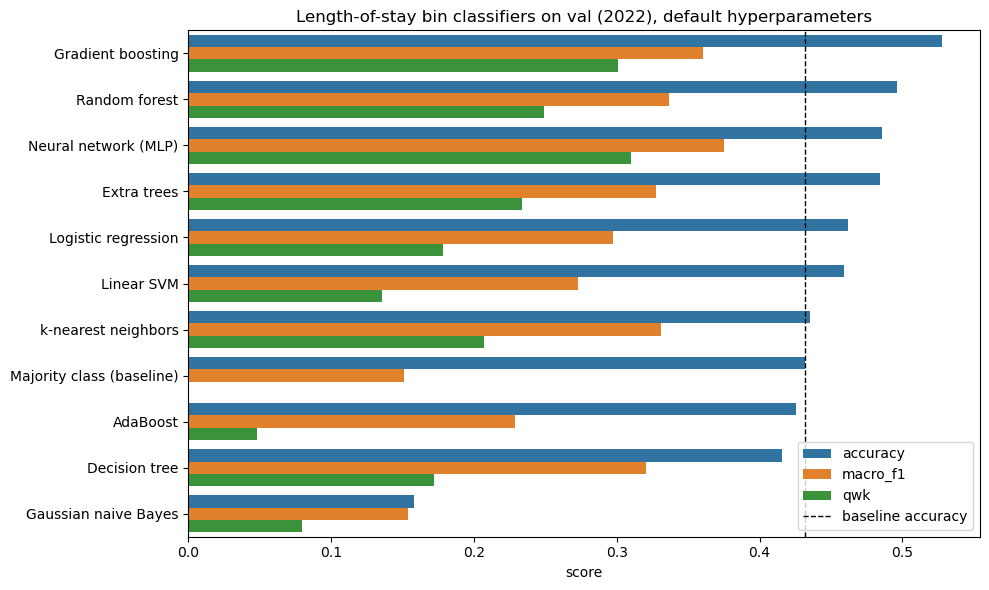

In [2]:
order = table.index
long = res.loc[order, ["accuracy", "macro_f1", "qwk"]].reset_index().melt("model", var_name="metric")
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=long, y="model", x="value", hue="metric", ax=ax)
baseline = res.loc["Majority class (baseline)", "accuracy"]
ax.axvline(baseline, color="k", ls="--", lw=1, label="baseline accuracy")
ax.set_title("Length-of-stay bin classifiers on val (2022), default hyperparameters")
ax.set_xlabel("score"); ax.set_ylabel(""); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
# Per-class recall: which bins can each model find?
recall = res.loc[order, [f"recall_{c}" for c in utils.LOS_BIN_LABELS]]
recall.columns = utils.LOS_BIN_LABELS
recall.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None)

,<1 week,1-4 weeks,1-3 months,3+ months
model,,,,
Gradient boosting,0.78,0.46,0.21,0.01
Random forest,0.80,0.33,0.24,0.01
Neural network (MLP),0.60,0.48,0.35,0.06
Extra trees,0.79,0.30,0.22,0.02
Logistic regression,0.82,0.18,0.26,0.01
Linear SVM,0.86,0.17,0.17,0.00
k-nearest neighbors,0.58,0.38,0.31,0.05
Majority class (baseline),1.00,0.00,0.00,0.00
AdaBoost,0.86,0.05,0.19,0.00


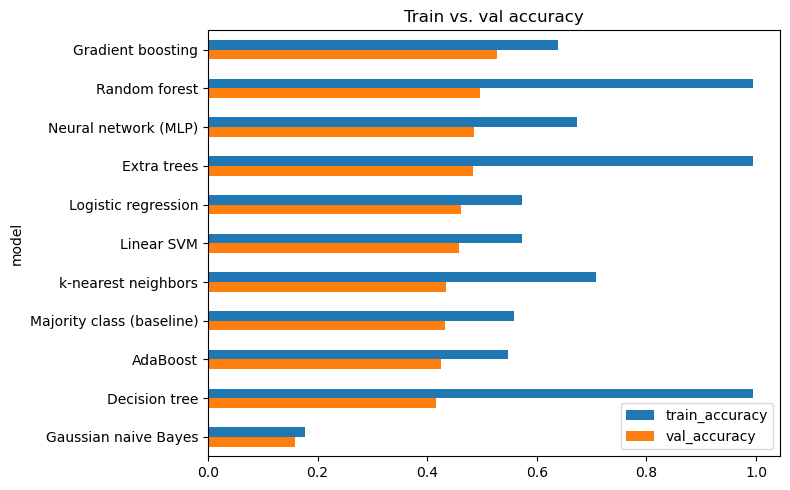

In [4]:
# Train vs. val accuracy: a large gap means overfitting (expected for untuned deep trees / 1-NN-like models)
ax = res.loc[order, ["train_accuracy", "accuracy"]].rename(columns={"accuracy": "val_accuracy"}).plot(
    kind="barh", figsize=(8, 5), title="Train vs. val accuracy")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## Takeaways (val = 2022, default hyperparameters)

| model | accuracy | macro-F1 | QWK | train acc |
|---|---|---|---|---|
| Gradient boosting | **0.528** | 0.360 | 0.301 | 0.638 |
| Random forest | 0.496 | 0.337 | 0.249 | 0.994 |
| Neural network (MLP) | 0.486 | **0.375** | **0.310** | 0.674 |
| Extra trees | 0.484 | 0.328 | 0.234 | 0.994 |
| Logistic regression | 0.462 | 0.297 | 0.179 | 0.574 |
| Linear SVM | 0.459 | 0.273 | 0.135 | 0.573 |
| k-nearest neighbors | 0.435 | 0.331 | 0.207 | 0.707 |
| *Majority class baseline* | *0.432* | *0.151* | *0.000* | *0.559* |
| AdaBoost | 0.425 | 0.228 | 0.048 | 0.548 |
| Decision tree | 0.416 | 0.321 | 0.172 | 0.994 |
| Gaussian naive Bayes | 0.158 | 0.154 | 0.080 | 0.177 |

- **Gradient boosting has the best accuracy** (+9.6 points over the baseline). **The MLP is best on macro-F1 and QWK**: it gives up some `<1 week` accuracy to find more of the longer-stay bins.
- **Length of stay is hard to predict from intake data alone.** Even the best model is only about 10 points above always predicting `<1 week`. A lot of stay length depends on things not known at intake (medical holds, foster availability, adopter demand).
- **`3+ months` is almost never predicted** (recall ≤ 9% for every real model). It is 4% of train, and no model here uses class weights. `class_weight="balanced"` or resampling is the obvious next step, judged on macro-F1 and QWK.
- **Deep trees overfit badly.** The decision tree, random forest and extra trees reach 99% train accuracy, against 42–50% on val. Tune `max_depth`, `min_samples_leaf` and `max_features` first.
- **The linear models (logistic regression, linear SVM) and AdaBoost's stumps underfit.** They mostly predict `<1 week`, so they can't capture interactions such as species × age.
- **Gaussian naive Bayes fails** (below the baseline). Its Gaussian assumption doesn't fit one-hot features, so it predicts `3+ months` for almost everything. Drop it, or replace it with `CategoricalNB` on the raw categories.
- **Some of the gap is drift, not just model error.** The val bins are longer than train (`<1 week` falls from 56% to 43%), so every model is biased toward short stays.

**Suggested shortlist for tuning:** gradient boosting, MLP, random forest. Run the tuning on train with time-ordered CV or on val, and score test only once at the end.

## After tuning

Each notebook 02–11 also ran a randomized search (`utils.tune_classifier`): fit on intakes before 2021, scored by macro-F1 on 2021, then refit on all training data. The table compares each model before and after tuning on the **same 2022 val set**.

In [5]:
tuned = all_res[all_res.index.str.endswith("(tuned)") & ~all_res.index.str.contains("Dog|Cat")].copy()
tuned.index = tuned.index.str.replace(" (tuned)", "", regex=False)
metrics_cols = ["accuracy", "macro_f1", "qwk"]
cmp = pd.concat({"untuned": res.loc[tuned.index, metrics_cols], "tuned": tuned[metrics_cols]}, axis=1)
for m in metrics_cols:
    cmp[("delta", m)] = cmp[("tuned", m)] - cmp[("untuned", m)]
cmp[("tuned", "train_accuracy")] = tuned["train_accuracy"]
cmp[("tuned", "minutes_tuning")] = tuned["tuning_minutes"]
cmp = cmp.sort_values(("tuned", "macro_f1"), ascending=False)
cmp.style.format("{:.3f}").format("{:.1f}", subset=[("tuned", "minutes_tuning")]) \
   .background_gradient(cmap="RdYlGn", subset=[("delta", m) for m in metrics_cols], vmin=-.1, vmax=.1)

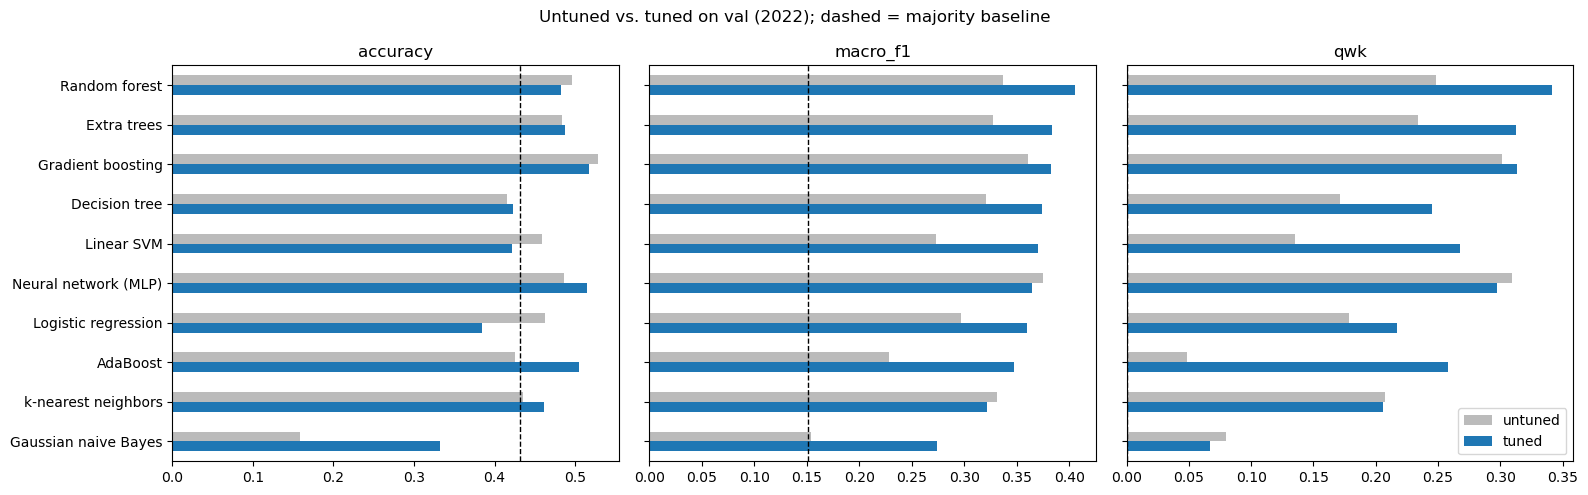

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
order_t = cmp.index
base_acc = res.loc["Majority class (baseline)"]
for ax, m in zip(axes, metrics_cols):
    d_ = pd.DataFrame({"untuned": cmp[("untuned", m)], "tuned": cmp[("tuned", m)]}).loc[order_t]
    d_.plot(kind="barh", ax=ax, legend=(m == "qwk"), color=["#bbbbbb", "C0"])
    ax.axvline(base_acc[m], color="k", ls="--", lw=1)
    ax.set_title(m); ax.invert_yaxis()
axes[0].set_ylabel("")
fig.suptitle("Untuned vs. tuned on val (2022); dashed = majority baseline")
plt.tight_layout()
plt.savefig("results/tuned_vs_untuned.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Best hyperparameters found
pd.Series({n.replace(" (tuned)", ""): r for n, r in all_res.loc[all_res.index.str.endswith("(tuned)") & ~all_res.index.str.contains("Dog|Cat"), "best_params"].items()}).to_frame("best_params")

,best_params
AdaBoost,"{'estimator__max_depth': 2, 'learning_rate': 1..."
Decision tree,"{'min_samples_leaf': 100, 'max_depth': 6, 'cri..."
Extra trees,"{'n_estimators': 100, 'min_samples_leaf': 2, '..."
Gaussian naive Bayes,{'var_smoothing': 0.25619560600751484}
Gradient boosting,"{'class_weight': None, 'l2_regularization': 0...."
k-nearest neighbors,"{'weights': 'uniform', 'n_neighbors': 15}"
Linear SVM,"{'C': 0.02161894240657444, 'class_weight': 'ba..."
Logistic regression,"{'C': 3.4702669886504163, 'class_weight': 'bal..."
Neural network (MLP),"{'alpha': 0.0005342937261279777, 'batch_size':..."
Random forest,"{'n_estimators': 300, 'min_samples_leaf': 5, '..."


In [8]:
# Tuned per-class recall
rec = tuned.loc[order_t, [f"recall_{c}" for c in utils.LOS_BIN_LABELS]]
rec.columns = utils.LOS_BIN_LABELS
rec.style.format("{:.2f}").background_gradient(cmap="Blues", axis=None)

,<1 week,1-4 weeks,1-3 months,3+ months
model,,,,
Random forest,0.52,0.54,0.40,0.16
Extra trees,0.65,0.41,0.35,0.11
Gradient boosting,0.74,0.45,0.24,0.07
Decision tree,0.30,0.63,0.38,0.31
Linear SVM,0.55,0.26,0.42,0.44
Neural network (MLP),0.69,0.52,0.24,0.02
Logistic regression,0.35,0.37,0.44,0.57
AdaBoost,0.75,0.42,0.24,0.01
k-nearest neighbors,0.69,0.35,0.27,0.01


## Takeaways after tuning (val = 2022)

| model | untuned acc / macro-F1 / QWK | tuned acc / macro-F1 / QWK | tuned "3+ months" recall | tuned train acc |
|---|---|---|---|---|
| Random forest | 0.496 / 0.337 / 0.249 | 0.483 / **0.405** / **0.342** | 0.16 | 0.798 |
| Extra trees | 0.484 / 0.327 / 0.234 | 0.487 / 0.384 / 0.313 | 0.11 | 0.960 |
| Gradient boosting | **0.528** / 0.360 / 0.301 | 0.517 / 0.383 / 0.314 | 0.07 | 0.690 |
| Decision tree | 0.416 / 0.321 / 0.172 | 0.423 / 0.374 / 0.245 | 0.31 | 0.443 |
| Linear SVM | 0.459 / 0.273 / 0.135 | 0.422 / 0.370 / 0.268 | 0.44 | 0.518 |
| Neural network (MLP) | 0.486 / 0.375 / 0.310 | 0.514 / 0.364 / 0.298 | 0.02 | 0.642 |
| Logistic regression | 0.462 / 0.297 / 0.179 | 0.385 / 0.360 / 0.217 | 0.57 | 0.445 |
| AdaBoost | 0.425 / 0.228 / 0.048 | 0.505 / 0.348 / 0.258 | 0.01 | 0.588 |
| k-nearest neighbors | 0.435 / 0.331 / 0.207 | 0.462 / 0.322 / 0.206 | 0.01 | 0.643 |
| Gaussian naive Bayes | 0.158 / 0.154 / 0.080 | 0.333 / 0.274 / 0.067 | 0.09 | 0.423 |
| *Majority baseline* | *0.432 / 0.151 / 0.000* | | | |

- **Best tuned model: random forest**, with the highest macro-F1 (0.405) and QWK (0.342). Its settings: class-balanced, 300 trees, depth 30, minimum 5 samples per leaf, 30% of features per split. Train accuracy fell from 0.994 to 0.798, so it overfits much less.
- **Class weighting drove most of the gains.** The search picked `class_weight="balanced"` for every model that supports it except gradient boosting. That trades accuracy for finding long stays: logistic regression drops to 0.385 accuracy but finds 57% of "3+ months" stays, up from 1%. Accuracy alone would rank these models backwards.
- **Small or negative changes:** MLP and k-NN got slightly worse on macro-F1, and gradient boosting lost a little accuracy. Settings were picked on 2021 and scored on 2022, so when the gain is small, the year-to-year drift can be bigger than the gain. This is the honest version of tuning, not a bug.
- **Ceiling:** the best macro-F1 is about 0.40 and QWK about 0.34, consistent with the earlier diagnosis that most of the variation in stay length isn't knowable at intake.
- **Shortlist for the final test-set evaluation:** tuned random forest (best balanced performance) and gradient boosting (best accuracy). Optionally, the class-weighted linear SVM or logistic regression as a high-recall screen for long stays.